In [36]:
import polars as pl

In [37]:
def show_all(df, width=200):
    '''
    Prints an entire polars dataframe in the console or notebook output.
    
    Parameters
    ----------
    df : pl.DataFrame
        The dataframe to be printed.
    width : int, optional
        The width (in characters) of the printed dataframe.
        Defaults to 200.
    '''
    with pl.Config() as cfg:
        cfg.set_tbl_cols(-1)
        cfg.set_tbl_rows(-1)
        cfg.set_tbl_width_chars(width)
        cfg.set_fmt_str_lengths(width)
        
        print(df)

In [ ]:
from Bio import Entrez
import polars as pl
import sys

Entrez.email = "n9985158@aquarius01.ib0.hpc.qut.edu.au"

# Target non-metazoan, non-plant TSA masters in nuccore
term = '("Eukaryota"[Organism] NOT "Metazoa"[Organism] NOT "Viridiplantae"[Organism]) AND tsa-master[prop]'

print("Searching nuccore database...")
handle = Entrez.esearch(db="nuccore", term=term, retmax=2000)
record = Entrez.read(handle)
handle.close()

id_list = record["IdList"]
print(f"Found {len(id_list)} nucleotide records.")

batch_size = 100
metadata = []

for start in range(0, len(id_list), batch_size):
    batch_ids = id_list[start:start + batch_size]
    
    try:
        # Use db="nuccore" to match the IDs you just retrieved
        handle = Entrez.esummary(db="nuccore", id=",".join(batch_ids))
        summaries = Entrez.read(handle)
        handle.close()
        
        for summary in summaries:
            metadata.append({
                "Accession": summary.get("AccessionVersion", ""),
                "Title": summary.get("Title", ""),
                "TaxID": summary.get("TaxId", ""),
                "Organism": summary.get("Organism", "")
            })
    except Exception as e:
        print(f"Error fetching batch starting at {start}: {e}", file=sys.stderr)

df = pl.DataFrame(metadata)


tax = pl.read_csv('/home/n9985158/phd/euk-singlem/metapackage_workflow/outputs/metadata/taxonomy_mapping.tsv', separator='\t')

unique_transcripts = (
    df
    .join(tax, left_on="TaxID", right_on="ncbi_id", how="anti")
    )

Searching nuccore database...
Found 1162 nucleotide records.
Saved metadata to nuccore_tsa_metadata.tsv


In [20]:
from Bio import Entrez
import sys
import time

Entrez.email = "n9985158@aquarius01.ib0.hpc.qut.edu.au"

# Generate the list of component accessions for GLPS00000000
# GLPS01000001 to GLPS01027749
prefix = "GLPS01"
start_num = 1
end_num = 27749

accessions = [f"{prefix}{i:06d}" for i in range(start_num, end_num + 1)]
output_fasta = "test/Coolia_malayensis_transcripts.fasta"

print(f"Downloading {len(accessions)} transcripts into {output_fasta}...")

batch_size = 50
with open(output_fasta, "w") as out_fh:
    for i in range(0, len(accessions), batch_size):
        batch = accessions[i:i + batch_size]
        print(f"Fetching batch {i+1} to {min(i+batch_size, len(accessions))}...")
        
        success = False
        retries = 3
        while retries > 0 and not success:
            try:
                handle = Entrez.efetch(
                    db="nuccore",
                    id=",".join(batch),
                    rettype="fasta",
                    retmode="text"
                )
                data = handle.read()
                handle.close()
                
                out_fh.write(data)
                success = True
                time.sleep(0.4) # Be polite to NCBI servers
            except Exception as e:
                retries -= 1
                print(f"Error encountered: {e}. Retries left: {retries}", file=sys.stderr)
                time.sleep(2)
        
        if not success:
            print(f"Failed permanently on batch starting with {batch[0]}", file=sys.stderr)

print("Download finished!")

Fetching batch 1 to 50...
Fetching batch 51 to 100...
Fetching batch 101 to 150...
Fetching batch 151 to 200...
Fetching batch 201 to 250...
Fetching batch 251 to 300...
Fetching batch 301 to 350...
Fetching batch 351 to 400...
Fetching batch 401 to 450...
Fetching batch 451 to 500...
Fetching batch 501 to 550...
Fetching batch 551 to 600...
Fetching batch 601 to 650...
Fetching batch 651 to 700...
Fetching batch 701 to 750...
Fetching batch 751 to 800...
Fetching batch 801 to 850...
Fetching batch 851 to 900...
Fetching batch 901 to 950...
Fetching batch 951 to 1000...
Fetching batch 1001 to 1050...
Fetching batch 1051 to 1100...
Fetching batch 1101 to 1150...
Fetching batch 1151 to 1200...
Fetching batch 1201 to 1250...
Fetching batch 1251 to 1300...
Fetching batch 1301 to 1350...
Fetching batch 1351 to 1400...
Fetching batch 1401 to 1450...
Fetching batch 1451 to 1500...
Fetching batch 1501 to 1550...
Fetching batch 1551 to 1600...
Fetching batch 1601 to 1650...
Fetching batch 1651 

In [44]:
print(
    pl.scan_csv(
        'data/fungi_meta.csv',
        # has_header=False,
    )
    .select(pl.col('NCBI Taxon').alias('tax_id'))
    .collect()
)

shape: (3_835, 1)
┌─────────┐
│ tax_id  │
│ ---     │
│ i64     │
╞═════════╡
│ 252194  │
│ 743928  │
│ 1738546 │
│ 252180  │
│ 252155  │
│ …       │
│ 31870   │
│ 150374  │
│ 5016    │
│ 1309686 │
│ 222929  │
└─────────┘


In [35]:
import os
from typing import Iterable

import polars as pl
from Bio import Entrez

Entrez.email = 'mitcheja@qut.edu.au'
term = f"txid2759[Organism:exp] AND latest[filter]"

# filter out meatazoa and plants (vir)
term += " NOT txid33208[Organism:exp] "
term += " NOT txid3193[Organism:exp]"

term += " AND reference[Properties]"

with Entrez.esearch(db="assembly", term=term, retmax=100000, usehistory="y") as handle:
    search = Entrez.read(handle)

ids = [str(value) for value in search.get("IdList", [])]
print(len(ids))

6600


In [29]:
def chunks(values: list[str], size: int) -> Iterable[list[str]]:
    for start in range(0, len(values), size):
        yield values[start:start + size]

rows = []

chunk_1 = [list(chunks(ids, 100))[0]]
for batch in chunk_1:
    with Entrez.esummary(db="assembly", id=",".join(batch), report="full") as handle:
        summary = Entrez.read(handle)
    documents = summary.get("DocumentSummarySet", {}).get("DocumentSummary", [])
    for document in documents:
        accession = str(document.get("AssemblyAccession", "")).strip()
        tax_id = str(document.get("Taxid", "")).strip()
        if accession and tax_id:
            rows.append({
                "genome_acc": accession,
                "tax_id": tax_id,
                "original_name": str(document.get("SpeciesName", "")).strip(),
                "download_source": "NCBI",
                "group": "ncbi",
            })

print(pl.DataFrame(rows).unique("genome_acc").sort("genome_acc"))

shape: (100, 5)
┌─────────────────┬─────────┬───────────────────────────┬─────────────────┬───────┐
│ genome_acc      ┆ tax_id  ┆ original_name             ┆ download_source ┆ group │
│ ---             ┆ ---     ┆ ---                       ┆ ---             ┆ ---   │
│ str             ┆ str     ┆ str                       ┆ str             ┆ str   │
╞═════════════════╪═════════╪═══════════════════════════╪═════════════════╪═══════╡
│ GCA_036768465.1 ┆ 29911   ┆ Alternaria brassicae      ┆ NCBI            ┆ ncbi  │
│ GCA_036867785.1 ┆ 37360   ┆ Plasmodiophora brassicae  ┆ NCBI            ┆ ncbi  │
│ GCA_036871495.1 ┆ 191334  ┆ Blastobotrys mucifer      ┆ NCBI            ┆ ncbi  │
│ GCA_037179535.1 ┆ 569361  ┆ Fusarium vorosii          ┆ NCBI            ┆ ncbi  │
│ GCA_037356215.2 ┆ 420259  ┆ Thalassiosira gravida     ┆ NCBI            ┆ ncbi  │
│ …               ┆ …       ┆ …                         ┆ …               ┆ …     │
│ GCF_001720195.1 ┆ 1295531 ┆ Cryptococcus depauperatus ┆ NC

In [13]:
off_target_reps = (
    pl.scan_csv([
        "/mnt/hpccs01/work/microbiome/db/gtdb/gtdb_release226/ar53_metadata_r226.tsv.gz",
        "/mnt/hpccs01/work/microbiome/db/gtdb/gtdb_release226/bac120_metadata_r226.tsv.gz"],
        separator='\t', has_header=True, ignore_errors=True
        )
    .select(['accession', 'gtdb_taxonomy', 'checkm2_completeness', 'checkm2_contamination', 'gtdb_representative'])
    .filter(pl.col('gtdb_representative') == 't')
    .with_columns(
        pl.col('gtdb_taxonomy').str.split(';').list.get(-3).alias('family')
    )
    .sort(['family', 'checkm2_completeness', 'checkm2_contamination'], descending=[False, True, False])
    .group_by('family')
    .head(1)
    .collect()
    ['accession']
    .to_list()
    )


print(len(off_target_reps))

5932


In [2]:
import csv
import json
import time
from pathlib import Path

import polars as pl
from Bio import Entrez

Entrez.email = "n9985158@aquarius01.ib0.hpc.qut.edu.au"

SOURCE_DIR = Path("outputs/metadata/source")


def jgi_release_rows(group: str) -> list[dict]:
    """Read JGI release dates from the largest file record per organism."""
    with open(SOURCE_DIR / "jgi" / f"{group}.json", encoding="utf-8") as handle:
        data = json.load(handle)

    rows = []
    for organism in data.get("organisms", []):
        files = organism.get("files", [])
        if not files:
            continue
        file_record = max(files, key=lambda item: item.get("file_size", 0))
        accession = file_record.get("portal_detail_id") or organism.get("portal_detail_id")
        if not accession:
            continue
        rows.append({
            "genome_acc": accession,
            "source": "JGI",
            "group": group,
            "release_date": file_record.get("file_date") or file_record.get("added_date"),
        })
    return rows


def p10k_release_rows() -> list[dict]:
    rows = []
    with open(SOURCE_DIR / "p10k" / "p10k_meta.csv", newline="", encoding="utf-8") as handle:
        for row in csv.DictReader(handle):
            accession = (row.get("Accession") or "").strip()
            if accession:
                rows.append({
                    "genome_acc": accession,
                    "source": "P10K",
                    "group": "p10k",
                    "release_date": (row.get("Release Date") or "").strip() or None,
                })
    return rows


def ncbi_release_rows(accessions: list[str], batch_size: int = 100) -> list[dict]:
    rows = []
    for start in range(0, len(accessions), batch_size):
        batch = accessions[start:start + batch_size]
        print(f"Querying NCBI release dates {start + 1}-{start + len(batch)} of {len(accessions)}...")
        with Entrez.esearch(db="assembly", term=" OR ".join(f'"{acc}"[Assembly Accession]' for acc in batch), retmax=len(batch)) as handle:
            search = Entrez.read(handle)
        ids = search.get("IdList", [])
        if not ids:
            continue
        with Entrez.esummary(db="assembly", id=",".join(ids), report="full") as handle:
            summary = Entrez.read(handle)
        documents = summary.get("DocumentSummarySet", {}).get("DocumentSummary", [])
        for document in documents:
            accession = str(document.get("AssemblyAccession", "")).strip()
            if not accession:
                continue
            release_date = (
                document.get("AssemblyReleaseDate")
                or document.get("ReleaseDate")
                or document.get("SubmissionDate")
            )
            rows.append({
                "genome_acc": accession,
                "source": "NCBI",
                "group": "ncbi",
                "release_date": str(release_date).strip() if release_date else None,
            })
        time.sleep(0.34)
    return rows


jgi_rows = jgi_release_rows("algae") + jgi_release_rows("fungi")
p10k_rows = p10k_release_rows()

with open(SOURCE_DIR / "ncbi" / "ncbi_genomes.tsv", encoding="utf-8") as handle:
    ncbi_accessions = [row["genome_acc"] for row in csv.DictReader(handle, delimiter="\t")]

release_dates_df = pl.DataFrame(
    jgi_rows + p10k_rows + ncbi_release_rows(ncbi_accessions),
    schema={
        "genome_acc": pl.String,
        "source": pl.String,
        "group": pl.String,
        "release_date": pl.String,
    },
).unique(["genome_acc", "source"])

release_dates_df = release_dates_df.with_columns(
    pl.col("release_date").str.to_datetime(strict=False).dt.date().alias("release_date")
).sort(["source", "release_date", "genome_acc"])

release_dates_df

Querying NCBI release dates 1-100 of 3763...
Querying NCBI release dates 101-200 of 3763...
Querying NCBI release dates 201-300 of 3763...
Querying NCBI release dates 301-400 of 3763...
Querying NCBI release dates 401-500 of 3763...
Querying NCBI release dates 501-600 of 3763...
Querying NCBI release dates 601-700 of 3763...
Querying NCBI release dates 701-800 of 3763...
Querying NCBI release dates 801-900 of 3763...
Querying NCBI release dates 901-1000 of 3763...
Querying NCBI release dates 1001-1100 of 3763...
Querying NCBI release dates 1101-1200 of 3763...
Querying NCBI release dates 1201-1300 of 3763...
Querying NCBI release dates 1301-1400 of 3763...
Querying NCBI release dates 1401-1500 of 3763...
Querying NCBI release dates 1501-1600 of 3763...
Querying NCBI release dates 1601-1700 of 3763...
Querying NCBI release dates 1701-1800 of 3763...
Querying NCBI release dates 1801-1900 of 3763...
Querying NCBI release dates 1901-2000 of 3763...
Querying NCBI release dates 2001-2100 of 

genome_acc,source,group,release_date
str,str,str,date
"""Aciri1_iso""","""JGI""","""fungi""",2012-03-07
"""Acral2""","""JGI""","""fungi""",2012-03-07
"""Agabi_varbisH97_2""","""JGI""","""fungi""",2012-03-07
"""Agabi_varbur_1""","""JGI""","""fungi""",2012-03-07
"""Altbr1""","""JGI""","""fungi""",2012-03-07
…,…,…,…
"""GCA_977970315.1""","""P10K""","""p10k""",2025-12-27
"""GCA_033557925.1""","""P10K""","""p10k""",2025-12-28
"""GCA_054131385.1""","""P10K""","""p10k""",2026-01-07


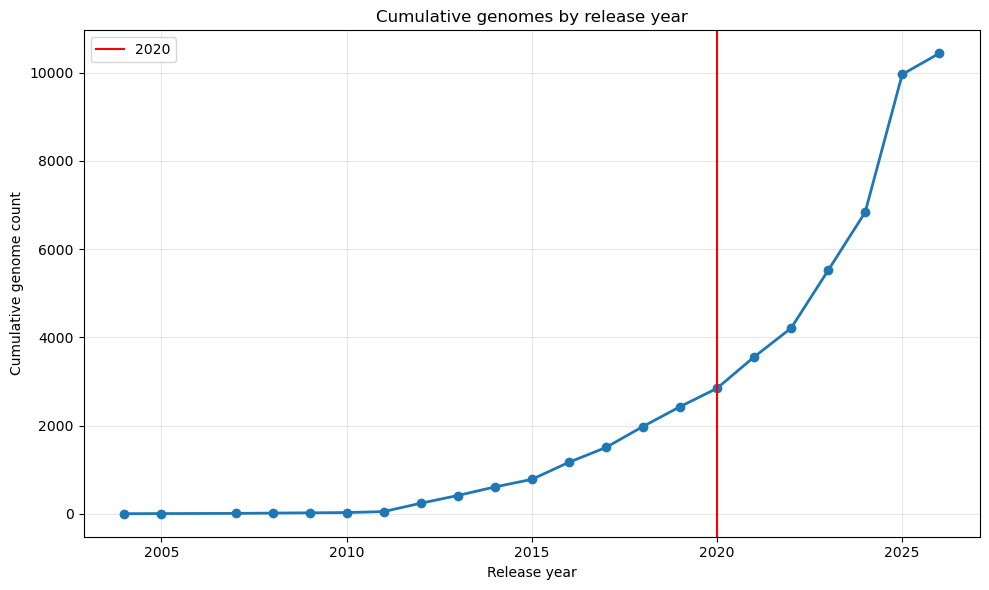

release_year,genome_count,cumulative_genome_count
i32,u32,u32
2004,1,1
2005,3,4
2007,4,8
2008,7,15
2009,6,21
…,…,…
2022,654,4207
2023,1309,5516
2024,1318,6834


In [3]:
import matplotlib.pyplot as plt

cumulative_release = (
    release_dates_df
    .drop_nulls("release_date")
    .with_columns(
        pl.col("release_date").dt.year().alias("release_year")
    )
    .group_by("release_year")
    .agg(pl.col("genome_acc").n_unique().alias("genome_count"))
    .sort("release_year")
    .with_columns(
        pl.col("genome_count").cum_sum().alias("cumulative_genome_count")
    )
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(
    cumulative_release["release_year"],
    cumulative_release["cumulative_genome_count"],
    marker="o",
    linewidth=2,
)
ax.axvline(2020, color="red", linewidth=1.5, label="2020")
ax.set_xlabel("Release year")
ax.set_ylabel("Cumulative genome count")
ax.set_title("Cumulative genomes by release year")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

cumulative_release